<a href="https://colab.research.google.com/github/sajal-01/PAB-prefix-anchor-bolding-algorithm/blob/main/PAB_Bold_Reader_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PAB – Prefix-Anchor Bolding for faster reading

This notebook converts text (from a **text PDF, a scanned PDF, an image, a .txt file, or pasted text**) so that the
**leading letters of every word are bold**, then rebuilds a **single combined PDF** where the original text is replaced page by page.

**Algorithm: PAB (Prefix-Anchor Bolding)**

| Word length | Letters bolded (from the left, always continuous) |
|---|---|
| 1 | 1 (whole word) |
| 2 | 1 |
| 3 | 2 |
| 4 | 2 |
| 5 | 2 or 3 |
| 6 | 3 |
| 7+ | 4 or 5 |

Where two options exist, the longer one is used **if the bold prefix is itself a common word / common prefix** (e.g. **high**lighted, **over**come); otherwise a length-based default is used. Punctuation is never bolded.

Run the cells from top to bottom.

In [1]:
# 1) Install dependencies (takes ~30 s on Colab)
!apt-get -qq install -y tesseract-ocr > /dev/null
!pip -q install pymupdf pytesseract pillow reportlab wordfreq

In [2]:
# 2) THE ALGORITHM: PAB (Prefix-Anchor Bolding)
import re, math, html

# Built-in fallback lexicon of very common words (used if `wordfreq` is unavailable)
_BASE_WORDS = """
a about above across act add after again against age ago air all also always am among an and animal another answer any are area
around as ask at away back bad ball base be bear beat because become bed been before began begin behind being believe below best
better between big bird black blue boat body book both box boy bring brother build but buy by call came can car care carry case
catch cause change child city class clean close cold color come common could country course cut dark day dead deep did die do
dog done door down draw dream drive drop dry during each ear early earth east easy eat end enough even ever every eye face fact
fall family far farm fast father feel feet few field fill find fine fire first fish five floor fly follow food foot for form found
four free friend from front full game gave get girl give go gold gone good got great green grew ground group grow had hair half
hand happen hard has have he head hear heart heavy help her here high him his hold home hope horse hot hour house how however hundred
idea if in inch into is it its just keep kind king knew know land large last late laugh lay lead learn leave left less let letter
life light like line list little live long look lot love low made make man many map mark may me mean measure men might mile mind
miss money month moon more morning most mother mountain move much music must my name near need never new next night no north not note
now number of off often oil old on once one only open or order other our out over own page paper part pass past pay people person
picture piece place plan plant play point power press pretty problem produce public pull put question quick rain ran reach read ready
real red remember rest right ring river road rock room round run safe said same sand saw say school sea second see seem sentence set
several shape she ship short should show side sign simple since sing sit six size sleep slow small snow so some song soon sound south
space speak special spell spend stand star start state stay step stick still stop story strong study such sun sure table take talk tall
teach tell ten than thank that the their them then there these they thing think this those though thought three through time to today
together told too took top toward town tree try turn two under until up upon us use usual very visit voice wait walk want war warm was
wash watch water way we weather week weight well went were west what wheel when where which while white who whole why will wind winter
wish with without woman word work world would write year yes yet you young your
attention deficit disorder reader readers book books fix point points focus brain rest initial high light highlight help method
technique special using hack
"""
_FALLBACK = set(_BASE_WORDS.split())

try:
    from wordfreq import top_n_list
    LEXICON = {w for w in top_n_list("en", 20000) if w.isalpha() and len(w) >= 2} | _FALLBACK
except Exception:
    LEXICON = _FALLBACK

# Very common prefixes that "make sense" as a bold anchor
AFFIXES = {
    "pre","pro","con","com","sub","dis","mis","non","out","over","under","inter","trans","anti","auto","semi",
    "super","fore","micro","multi","hyper","extra","counter","mid","mini","imp","inc","exp","ext","res","rep",
    "dec","def","dem","det","dir","dev","ref","rec","rel","per","sup","sus","sur","uni","tri","bio","geo","tele",
}

# (min_bold, max_bold) for each word length – this is the table from the spec
_RANGE = {1: (1, 1), 2: (1, 1), 3: (2, 2), 4: (2, 2), 5: (2, 3), 6: (3, 3)}

def _default_bold(n: int) -> int:
    """Length-based fallback when no 'meaningful' prefix is found."""
    if n in _RANGE:
        return _RANGE[n][0]
    return min(5, max(4, math.ceil(n * 0.45)))     # 7-8 -> 4, 9+ -> 5

def bold_length(word: str) -> int:
    """How many leading letters of `word` must be bold (always a continuous run from index 0)."""
    n = len(word)
    if n <= 2:
        return 1
    lo, hi = _RANGE.get(n, (4, 5))
    low = word.lower()
    for k in range(hi, lo - 1, -1):          # prefer the longest valid prefix
        if k < n and (low[:k] in LEXICON or low[:k] in AFFIXES):
            return k                           # "highly favoured": the bold part makes sense
    return _default_bold(n)                    # otherwise still acceptable

# A word = letters/digits (any language). Anything after an apostrophe (e.g. 's, n't) stays plain.
_WORD_RE = re.compile(r"[^\W_]+(?:['\u2019][^\W_]+)*", re.UNICODE)

def pab_segments(text: str):
    """Yield (chunk, is_bold) pairs for the whole text. Punctuation/whitespace are never bold."""
    pos = 0
    for m in _WORD_RE.finditer(text):
        if m.start() > pos:
            yield text[pos:m.start()], False
        token = m.group()
        core = re.match(r"[^\W_]+", token).group()
        k = bold_length(core)
        yield core[:k], True
        rest = token[k:]
        if rest:
            yield rest, False
        pos = m.end()
    if pos < len(text):
        yield text[pos:], False

def pab_html(text: str) -> str:
    """Text -> HTML with <b>..</b> on the bold parts (newlines become <br/>)."""
    out = []
    for chunk, b in pab_segments(text):
        c = html.escape(chunk, quote=False).replace("\n", "<br/>")
        out.append(f"<b>{c}</b>" if b else c)
    return "".join(out)

def pab_markdown(text: str) -> str:
    return "".join(f"**{c}**" if b else c for c, b in pab_segments(text))

# quick demo
demo = "A new hack, which is being hailed as a blessing for people with Attention Deficit Hyperactivity Disorder, can help people read books almost twice as fast."
print(pab_markdown(demo))

**A** **ne**w **ha**ck, **wh**ich **i**s **be**ing **hai**led **a**s **a** **bless**ing **fo**r **peo**ple **wi**th **Atten**tion **Defi**cit **Hyper**activity **Diso**rder, **ca**n **he**lp **peo**ple **re**ad **boo**ks **alm**ost **tw**ice **a**s **fa**st.


In [3]:
# 3) Extraction: PDF (text or scanned), images, .txt  ->  page "blocks" (bbox + text + font size)
import os, io, fitz, pytesseract
from PIL import Image
from statistics import median

OCR_DPI = 200

def ocr_blocks(pil_img, scale=1.0):
    """OCR an image -> list of blocks {bbox:(x0,y0,x1,y1), text, size, color}. `scale` converts px -> PDF points."""
    d = pytesseract.image_to_data(pil_img, output_type=pytesseract.Output.DICT)
    paras = {}
    for i, word in enumerate(d["text"]):
        if not word.strip() or float(d["conf"][i]) < 0:
            continue
        key = (d["block_num"][i], d["par_num"][i])
        x, y, w, h = d["left"][i], d["top"][i], d["width"][i], d["height"][i]
        p = paras.setdefault(key, {"words": [], "boxes": [], "lines": {}})
        p["words"].append(word)
        p["boxes"].append((x, y, x + w, y + h))
        p["lines"].setdefault(d["line_num"][i], []).append(h)
    blocks = []
    for p in paras.values():
        x0 = min(b[0] for b in p["boxes"]); y0 = min(b[1] for b in p["boxes"])
        x1 = max(b[2] for b in p["boxes"]); y1 = max(b[3] for b in p["boxes"])
        line_h = median([max(v) for v in p["lines"].values()])
        blocks.append({"bbox": (x0*scale, y0*scale, x1*scale, y1*scale), "text": " ".join(p["words"]),
                       "size": max(5.0, line_h * scale * 0.78), "color": "#000000"})
    return blocks

def pdf_text_blocks(page):
    """Native text blocks of a PDF page (None if the page has no text layer)."""
    blocks = []
    for b in page.get_text("dict")["blocks"]:
        if b.get("type") != 0:
            continue
        lines, sizes, color = [], [], 0
        for ln in b["lines"]:
            t = "".join(s["text"] for s in ln["spans"]).strip()
            if t:
                lines.append(t)
            for s in ln["spans"]:
                if s["text"].strip():
                    sizes.append(s["size"]); color = s["color"]
        if lines:
            blocks.append({"bbox": tuple(b["bbox"]), "text": " ".join(lines),
                           "size": median(sizes), "color": "#%06x" % color})
    return blocks or None

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


In [4]:
# 4) Rendering: replace the original text with PAB text, page by page
CSS = "* {{ font-family: sans-serif; font-size: {size:.1f}pt; line-height: 1.2; color: {color}; margin:0; padding:0; }}"

def draw_blocks(page, blocks):
    for b in blocks:
        rect = fitz.Rect(b["bbox"])
        html_text = "<p>" + pab_html(b["text"]) + "</p>"
        # bold glyphs are a little wider: give the box a small safety margin to the right
        rect = fitz.Rect(rect.x0, rect.y0, min(rect.x1 + 4, page.rect.x1 - 2), rect.y1 + 2)
        page.insert_htmlbox(rect, html_text, css=CSS.format(size=b["size"], color=b["color"]), scale_low=0)

def convert_pdf(path, log):
    doc = fitz.open(path)
    out_doc = fitz.open()
    for pno, page in enumerate(doc, 1):
        blocks = pdf_text_blocks(page)
        if blocks:                                       # --- text PDF: edit in place
            for b in blocks:
                page.add_redact_annot(fitz.Rect(b["bbox"]), fill=(1, 1, 1))
            try:
                page.apply_redactions(images=fitz.PDF_REDACT_IMAGE_NONE)
            except TypeError:
                page.apply_redactions()
            draw_blocks(page, blocks)
            out_doc.insert_pdf(doc, from_page=pno-1, to_page=pno-1)
            mode = "text layer"
        else:                                            # --- scanned page: OCR then rebuild
            pix = page.get_pixmap(dpi=OCR_DPI)
            img = Image.open(io.BytesIO(pix.tobytes("png")))
            blocks = ocr_blocks(img, scale=72.0 / OCR_DPI)
            new = out_doc.new_page(width=page.rect.width, height=page.rect.height)
            draw_blocks(new, blocks)
            mode = "OCR"
        log.append((os.path.basename(path), pno, mode, "\n\n".join(b["text"] for b in blocks)))
    return out_doc

def convert_image(path, log):
    img = Image.open(path).convert("RGB")
    blocks = ocr_blocks(img, scale=1.0)
    out_doc = fitz.open()
    page = out_doc.new_page(width=img.width, height=img.height)
    draw_blocks(page, blocks)
    log.append((os.path.basename(path), 1, "OCR", "\n\n".join(b["text"] for b in blocks)))
    return out_doc

def convert_text(text, name, log):
    from reportlab.lib.pagesizes import A4
    from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer
    from reportlab.lib.styles import ParagraphStyle
    buf = io.BytesIO()
    style = ParagraphStyle("pab", fontName="Helvetica", fontSize=11, leading=16)
    story = []
    for para in re.split(r"\n\s*\n", text.strip()):
        story += [Paragraph(pab_html(para.strip()), style), Spacer(1, 8)]
    SimpleDocTemplate(buf, pagesize=A4, leftMargin=54, rightMargin=54, topMargin=54, bottomMargin=54).build(story)
    log.append((name, 1, "text", text))
    return fitz.open(stream=buf.getvalue(), filetype="pdf")

In [5]:
# 5) RUN  –  upload files (PDF / image / .txt)  or  paste text
INPUT_MODE = "upload"      # "upload"  or  "paste"
PASTED_TEXT = """A new hack, which is being hailed as a blessing for people with Attention Deficit Hyperactivity Disorder,
can help people read books almost twice as fast and with more focus."""

from google.colab import files

jobs = []   # list of (kind, path_or_text, name)
if INPUT_MODE == "upload":
    up = files.upload()
    for name in up:
        ext = os.path.splitext(name)[1].lower()
        if ext == ".pdf":                                   jobs.append(("pdf", name, name))
        elif ext in (".png", ".jpg", ".jpeg", ".bmp", ".tiff", ".webp"): jobs.append(("img", name, name))
        elif ext == ".txt":                                 jobs.append(("txt", open(name, encoding="utf-8", errors="ignore").read(), name))
        else: print("Skipped unsupported file:", name)
else:
    jobs.append(("txt", PASTED_TEXT, "pasted_text"))

log, final = [], fitz.open()
for kind, src, name in jobs:
    print("Processing:", name)
    if kind == "pdf":   part = convert_pdf(src, log)
    elif kind == "img": part = convert_image(src, log)
    else:               part = convert_text(src, name, log)
    final.insert_pdf(part)          # combine everything, page by page, in upload order

OUT_PDF = "pab_converted.pdf"
final.save(OUT_PDF, garbage=3, deflate=True)
print(f"\nDone: {len(final)} page(s) -> {OUT_PDF}")

# converted text (markdown: **bold**), page by page
md_out = []
for fname, pno, mode, txt in log:
    md_out.append(f"----- {fname} | page {pno} | {mode} -----\n{pab_markdown(txt)}\n")
open("pab_converted.md", "w", encoding="utf-8").write("\n".join(md_out))
print("\n".join(md_out)[:3000])

Saving DeepLearningBook-MIT-input.pdf to DeepLearningBook-MIT-input.pdf
Processing: DeepLearningBook-MIT-input.pdf

Done: 72 page(s) -> pab_converted.pdf
----- DeepLearningBook-MIT-input.pdf | page 1 | text layer -----
**De**ep **Learn**ing

**Ia**n **Good**fellow

**Yos**hua **Ben**gio **Aa**ron **Courv**ille

----- DeepLearningBook-MIT-input.pdf | page 2 | text layer -----
**Chap**ter **1**

**Intro**duction

**Inven**tors **ha**ve **lo**ng **dream**ed **o**f **crea**ting **mach**ines **th**at **th**ink. **Th**is **des**ire **dat**es **ba**ck **t**o **a**t **lea**st **th**e **ti**me **o**f **anci**ent **Gre**ece. **Th**e **myth**ical **ﬁgu**res **Pygma**lion, **Daed**alus, **an**d **Hepha**estus **ma**y **al**l **b**e **inter**preted **a**s **legen**dary **inven**tors, **an**d **Gala**tea, **Ta**los, **an**d **Pand**ora **ma**y **al**l **b**e **rega**rded **a**s **artiﬁ**cial **li**fe ( , **Ov**id **an**d **Mar**tin **20**04 **Spark**es **19**96 **Tan**dy **19**97 ; , ; , ).

**Wh**e

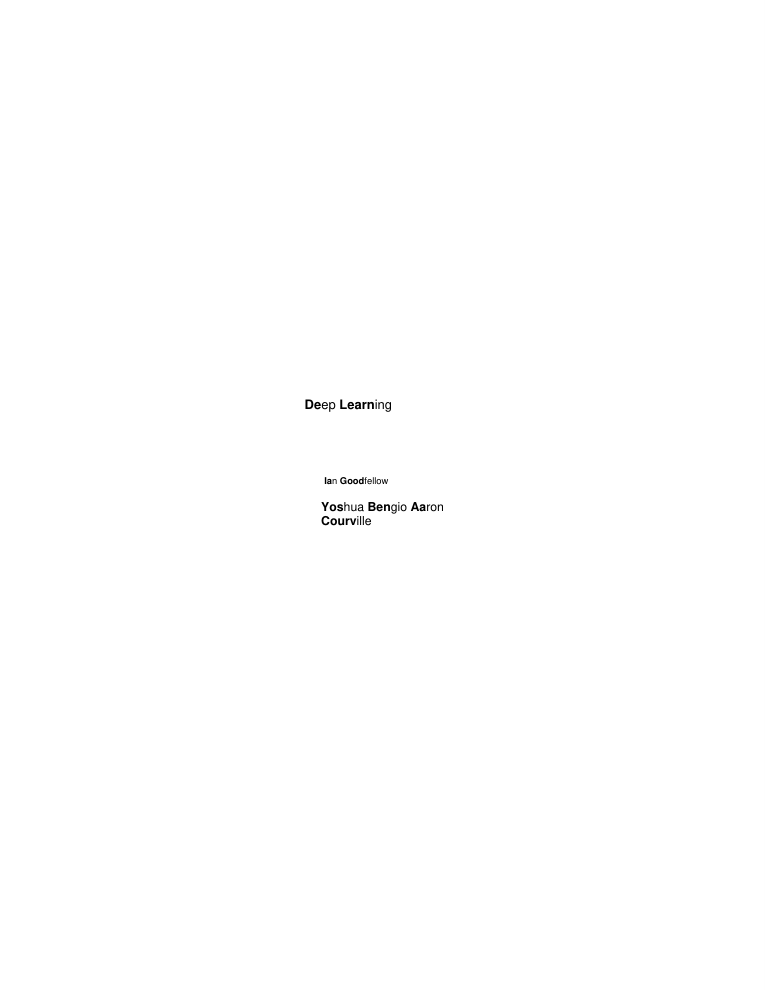

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
# 6) Preview first page + download
from IPython.display import display
pix = final[0].get_pixmap(dpi=90)
display(Image.open(io.BytesIO(pix.tobytes("png"))))
files.download(OUT_PDF)
files.download("pab_converted.md")